# 02 - k-Nearest Neighbours

Our implementation is in `src/knn.py`. Everything is measured on the same 80/20 validation split.

What we try:
1. **preprocessing** and **distance function** (Euclidean, cosine, and for the image histograms
   also histogram intersection and chi-squared)
2. **k**: 1 to 200
3. **voting**: equal votes vs distance-weighted votes, and how strongly closer neighbours count

Then we check over/underfitting, look at *why* images and tweets behave differently, and use
5-fold cross-validation to make sure our best image setting is not just lucky on one split.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_split, load_task, kfold_split, N_CLASSES, SEED
from src.preprocessing import Preprocessor
from src.knn import KNNClassifier
from src.utils import COLORS, accuracy, Timer, save_table, save_figure, save_predictions, set_seed

set_seed()
splits = {task: get_split(task) for task in ("image", "sentiment")}
K_VALUES = [1, 3, 5, 10, 20, 50, 100, 200]

# (preprocessing, distance) combinations to try. Intersection and chi2 need non-negative
# histograms, so they are only used on the image features without standardizing.
CONFIGS = {
    "image": [(p, m) for p in ("none", "standardize", "hellinger", "hellinger+standardize")
              for m in ("euclidean", "cosine")]
             + [(p, m) for p in ("none", "hellinger") for m in ("intersection", "chi2")],
    "sentiment": [(p, m) for p in ("none", "standardize", "l2") for m in ("euclidean", "cosine")],
}

## 1. Preprocessing x distance x k x voting

Finding the neighbours is the slow part, so for each (preprocessing, distance) we search the
200 nearest neighbours once, and then every smaller k and both voting rules reuse that list.

In [2]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for prep_mode, metric in CONFIGS[task]:
        prep = Preprocessor(prep_mode).fit(Xtr)          # fitted on the training split only
        knn = KNNClassifier(metric=metric, n_classes=N_CLASSES[task]).fit(prep.transform(Xtr), ytr)
        with Timer() as t:
            dist, idx = knn.kneighbors(prep.transform(Xva), k=max(K_VALUES))
        for k in K_VALUES:
            for weights in ("uniform", "distance"):
                pred = knn.vote(dist, idx, k, weights).argmax(1)
                rows.append(dict(task=task, preprocessing=prep_mode, metric=metric, k=k,
                                 weights=weights, val_acc=accuracy(yva, pred)))
        print(f"{task:9s} {prep_mode:22s} {metric:12s} neighbour search {t.seconds:.1f}s")
sweep = pd.DataFrame(rows)
save_table(sweep, "knn_sweep")

image     none                   euclidean    neighbour search 1.5s


image     none                   cosine       neighbour search 0.9s


image     standardize            euclidean    neighbour search 1.2s


image     standardize            cosine       neighbour search 0.9s


image     hellinger              euclidean    neighbour search 1.2s


image     hellinger              cosine       neighbour search 0.8s


... (8 outputs left out)

sentiment standardize            euclidean    neighbour search 0.6s


sentiment standardize            cosine       neighbour search 0.5s


sentiment l2                     euclidean    neighbour search 0.5s


sentiment l2                     cosine       neighbour search 0.5s


In [3]:
# best validation accuracy (over k and voting rule) of every preprocessing / distance combination
for task in splits:
    print(f"\n{task}")
    print(sweep[sweep.task == task].pivot_table(index="preprocessing", columns="metric",
                                                values="val_acc", aggfunc="max").round(4))


image
metric                   chi2  cosine  euclidean  intersection
preprocessing                                                 
hellinger              0.5715  0.5630     0.5630        0.5815
hellinger+standardize     NaN  0.5630     0.5118           NaN
none                   0.5790  0.5192     0.5192        0.5890
standardize               NaN  0.5332     0.4300           NaN

sentiment
metric         cosine  euclidean
preprocessing                   
l2             0.5896     0.5871
none           0.5896     0.5867
standardize    0.5892     0.5829


**Images: the distance function matters most.**
* With cosine/Euclidean, the raw histograms give 51.9% and the Hellinger transform 56.3%: taking
  square roots stops a few very frequent visual words from dominating. Standardizing the raw
  histograms with Euclidean distance *hurts* (43.0%), because it blows up rare, noisy words.
* On the raw features Euclidean and cosine are identical: every vector has length 1, and then
  ||a - b||^2 = 2 - 2 cos(a, b), so both find the same neighbours.
* **Histogram intersection** is clearly the best (58.9% here, before tuning the votes). It
  adds up min(a_i, b_i), so a very frequent word can only count as much as *both* images share
  of it: the damping that Hellinger does by hand is built into the distance. That is also why it
  works best on the raw histograms. Chi-squared is second (57.9%).

**Sentiment: almost nothing matters.** Every combination is within about 0.7% (58.3-59.0%).

## 2. Effect of k

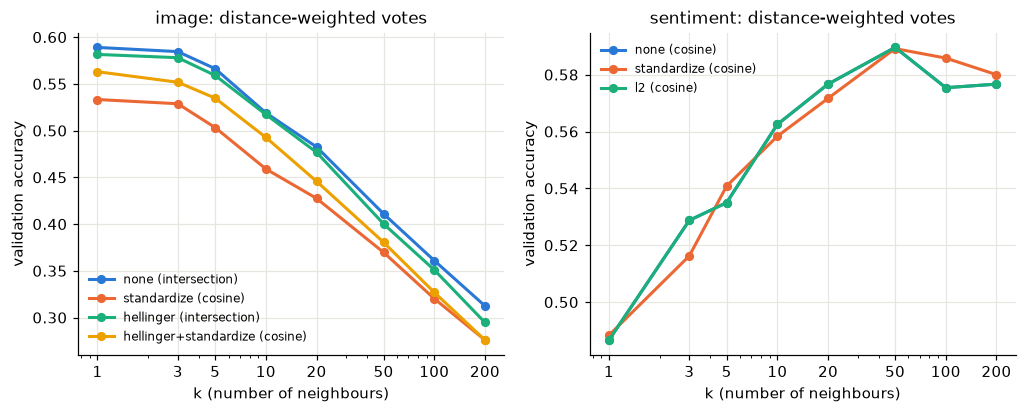

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    r = sweep[(sweep.task == task) & (sweep.weights == "distance")]
    for j, prep_mode in enumerate(r.preprocessing.unique()):
        rp = r[r.preprocessing == prep_mode]
        metric = rp.groupby("metric").val_acc.max().idxmax()     # best distance for this preprocessing
        rp = rp[rp.metric == metric].sort_values("k")
        ax.plot(rp.k, rp.val_acc, marker="o", color=COLORS[j], label=f"{prep_mode} ({metric})")
    ax.set_xscale("log")
    ax.set_xticks(K_VALUES)
    ax.set_xticklabels(K_VALUES)
    ax.set_xlabel("k (number of neighbours)")
    ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task}: distance-weighted votes")
    ax.legend(fontsize=8)
save_figure(fig, "02_knn_k_curves")
plt.show()

In [5]:
# how much do distance-weighted votes help, on average, compared with equal votes?
pv = sweep.pivot_table(index=["task", "preprocessing", "metric", "k"], columns="weights", values="val_acc").reset_index()
pv["distance_minus_uniform"] = pv["distance"] - pv["uniform"]
print(pv.groupby(["task", "k"]).distance_minus_uniform.mean().unstack(0).round(4))

task   image  sentiment
k                      
1     0.0000     0.0000
3     0.0001     0.0005
5     0.0031     0.0051
10    0.0104     0.0027
20    0.0162     0.0017
50    0.0127     0.0018
100   0.0123     0.0012
200   0.0108     0.0022


Distance-weighted votes basically never hurt, and help more as k grows (about +1 to +1.5 points
for images at k >= 10): with many neighbours, the far ones should have less say.
At k = 1 the two rules are the same thing.

## 3. How strongly should closer neighbours count?

Normal distance weighting is weight = 1/distance. We also try 1/distance^p for bigger p, which
lets the few closest neighbours dominate while the others only break near-ties. We run this on
the best cosine setting and the best intersection setting for images, and the best sentiment setting.

In [6]:
POWERS = [1, 2, 4, 8, 16]
POWER_CONFIGS = {"image": [("hellinger+standardize", "cosine"), ("none", "intersection")],
                 "sentiment": [("none", "cosine")]}
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for prep_mode, metric in POWER_CONFIGS[task]:
        prep = Preprocessor(prep_mode).fit(Xtr)
        knn = KNNClassifier(metric=metric, n_classes=N_CLASSES[task]).fit(prep.transform(Xtr), ytr)
        dist, idx = knn.kneighbors(prep.transform(Xva), k=max(K_VALUES))
        for k in K_VALUES[1:]:
            for p in POWERS:
                pred = knn.vote(dist, idx, k, "distance", p).argmax(1)
                rows.append(dict(task=task, preprocessing=prep_mode, metric=metric, k=k,
                                 weights="distance", power=p, val_acc=accuracy(yva, pred)))
powers = pd.DataFrame(rows)
save_table(powers, "knn_power_sweep")
for (task, metric), r in powers.groupby(["task", "metric"], sort=False):
    print(f"\n{task}, {r.preprocessing.iloc[0]}, {metric}")
    print(r.pivot(index="k", columns="power", values="val_acc").round(4))


image, hellinger+standardize, cosine
power      1       2       4       8       16
k                                            
3      0.5518  0.5535  0.5585  0.5638  0.5672
5      0.5347  0.5395  0.5550  0.5668  0.5728
10     0.4928  0.5025  0.5365  0.5658  0.5780
20     0.4458  0.4640  0.5112  0.5588  0.5788
50     0.3805  0.4090  0.4652  0.5448  0.5768
100    0.3270  0.3565  0.4278  0.5285  0.5805
200    0.2760  0.3020  0.3832  0.5012  0.5780

image, none, intersection
power      1       2       4       8       16
k                                            
3      0.5845  0.5853  0.5895  0.5942  0.5958
5      0.5662  0.5692  0.5822  0.5938  0.5988
10     0.5190  0.5272  0.5552  0.5910  0.6058
20     0.4825  0.4965  0.5345  0.5873  0.6148
50     0.4110  0.4325  0.4888  0.5618  0.6122
100    0.3610  0.3852  0.4408  0.5385  0.6130
200    0.3125  0.3392  0.3998  0.5135  0.6070

sentiment, none, cosine
power      1       2       4       8       16
k                                   

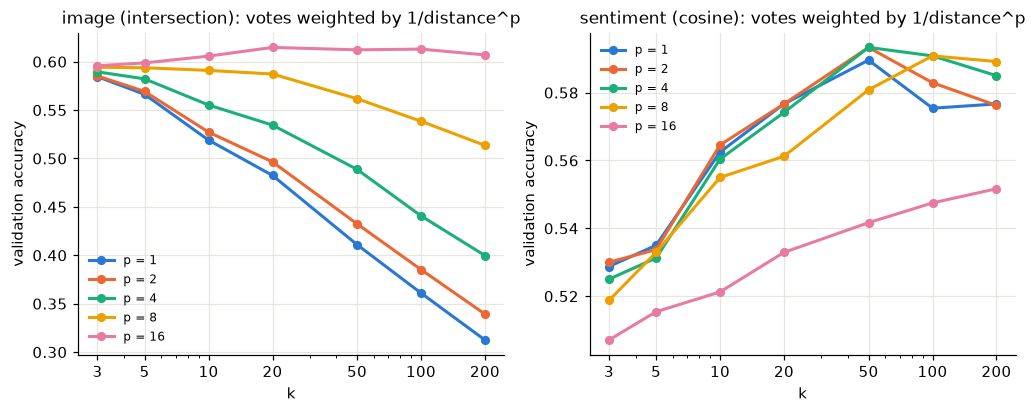

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (task, metric) in zip(axes, [("image", "intersection"), ("sentiment", "cosine")]):
    r = powers[(powers.task == task) & (powers.metric == metric)]
    for j, p in enumerate(POWERS):
        rp = r[r.power == p].sort_values("k")
        ax.plot(rp.k, rp.val_acc, marker="o", color=COLORS[j], label=f"p = {p}")
    ax.set_xscale("log")
    ax.set_xticks(K_VALUES[1:])
    ax.set_xticklabels(K_VALUES[1:])
    ax.set_xlabel("k")
    ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task} ({metric}): votes weighted by 1/distance^p")
    ax.legend(fontsize=8)
save_figure(fig, "02_knn_power")
plt.show()

In [8]:
# best setting per task (stable sort: on a tie, keep the first one in the table)
best = {task: powers[powers.task == task].sort_values("val_acc", ascending=False, kind="stable").iloc[0]
        for task in splits}
for task, b in best.items():
    print(f"{task}: {b.preprocessing}, {b.metric}, k={b.k}, 1/d^{b.power} -> {b.val_acc:.4f}")
cos = powers[(powers.task == "image") & (powers.metric == "cosine")].val_acc.max()
print(f"(best image setting with cosine distance: {cos:.4f})")

image: none, intersection, k=20, 1/d^16 -> 0.6148
sentiment: none, cosine, k=50, 1/d^2 -> 0.5933
(best image setting with cosine distance: 0.5805)


* **Images:** a high power (p = 16) is best at every k. With cosine distance this lifts the best
  result from 56.3% (1-NN) to 58.05% (k = 100). With **histogram intersection, k = 20 and
  1/d^16 we reach 61.5%**, our final image k-NN.
* **Sentiment:** mild weighting (p = 2-4, k = 50) is best and very high powers hurt: here,
  averaging many votes is what helps. Final: raw features, cosine, k = 50, 1/d^2 -> 59.3%.

## 4. Over- and under-fitting as k changes
"Training accuracy" = predicting training points with the training set as memory, so each point
is its own nearest neighbour and k = 1 scores 100% (pure memorization). Equal votes, final distance.

In [9]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    b = best[task]
    prep = Preprocessor(b.preprocessing).fit(Xtr)
    A, B = prep.transform(Xtr), prep.transform(Xva)
    knn = KNNClassifier(metric=b.metric, n_classes=N_CLASSES[task]).fit(A, ytr)
    some_train = np.random.default_rng(SEED).choice(len(A), 3000, replace=False)
    d_tr, i_tr = knn.kneighbors(A[some_train], k=max(K_VALUES))
    d_va, i_va = knn.kneighbors(B, k=max(K_VALUES))
    for k in K_VALUES:
        rows.append(dict(task=task, k=k,
                         train_acc=accuracy(ytr[some_train], knn.vote(d_tr, i_tr, k, "uniform").argmax(1)),
                         val_acc=accuracy(yva, knn.vote(d_va, i_va, k, "uniform").argmax(1))))
fit_curve = pd.DataFrame(rows)
fit_curve.pivot(index="k", columns="task", values=["train_acc", "val_acc"]).round(3)

train_acc           val_acc          
task     image sentiment   image sentiment
k                                         
1        1.000     1.000   0.589     0.487
3        0.972     0.807   0.584     0.528
5        0.902     0.744   0.562     0.527
10       0.766     0.668   0.506     0.558
20       0.656     0.640   0.466     0.574
50       0.523     0.608   0.396     0.586
100      0.428     0.587   0.346     0.573
200      0.352     0.576   0.298     0.575

* **Images:** validation accuracy is highest at small k and drops as k grows. Large k
  **underfits**: it blurs nearby groups (often from other classes) together.
* **Sentiment:** k = 1 is the worst. One neighbour is a noisy vote, i.e. **overfitting** to single
  training tweets. Accuracy improves up to k of about 50 and then flattens.

## 5. Why do the closest neighbours matter so much for images but not for tweets?
We group the validation points by how close their single nearest training point is, and check
how often that nearest neighbour has the right label.

In [10]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    b = best[task]
    prep = Preprocessor(b.preprocessing).fit(Xtr)
    knn = KNNClassifier(metric=b.metric, n_classes=N_CLASSES[task]).fit(prep.transform(Xtr), ytr)
    d, i = knn.kneighbors(prep.transform(Xva), k=1)
    correct = ytr[i[:, 0]] == yva
    group = pd.qcut(d[:, 0], 5, labels=["1 closest 20%", "2", "3", "4", "5 farthest 20%"])
    for g in group.categories:
        rows.append(dict(task=task, nearest_neighbour_distance=g, one_nn_accuracy=correct[np.asarray(group == g)].mean()))
by_distance = pd.DataFrame(rows)
by_distance.pivot(index="nearest_neighbour_distance", columns="task", values="one_nn_accuracy").round(3)

task,image,sentiment
nearest_neighbour_distance,,
1 closest 20%,0.930,0.521
2,0.739,0.525
3,0.629,0.465
4,0.448,0.479
5 farthest 20%,0.199,0.444


**Images:** when the nearest training image is very close (closest 20%), 1-NN is right 93% of
the time; when it is far (farthest 20%), only 20%. So each image class looks like many small, tight groups of
near-relatives (probably several photos of the same object). If a validation image has a
relative in the training set, its closest neighbour finds it, and extra equal votes only bring
in other groups. That is why the best setting listens mostly to the closest few (1/d^16).

**Sentiment:** the distance of the nearest neighbour barely predicts whether it is right. There
are no tight groups and the labels are noisy, so it pays to average many neighbours.

## 6. Is intersection really better, or just lucky on our split? (5-fold cross-validation)

All the numbers above come from one validation split, and the best settings were *chosen* on it,
so they are a bit optimistic. Here we fix two image settings in advance and re-score them with
5-fold CV on all 20,000 training images (train on 16,000, test on 4,000, five times).
Both settings see the same folds, so we can compare them fold by fold.

In [11]:
CV_CANDIDATES = {
    "cosine (hellinger+standardize, k=100, 1/d^16)": ("hellinger+standardize", "cosine", 100),
    "intersection (raw, k=20, 1/d^16)": ("none", "intersection", 20),
}
X_all, y_all, _, _ = load_task("image")
rows = []
for fold, (tr, va) in enumerate(kfold_split(y_all, n_folds=5)):
    for name, (prep_mode, metric, k) in CV_CANDIDATES.items():
        prep = Preprocessor(prep_mode).fit(X_all[tr])
        knn = KNNClassifier(k=k, metric=metric, weights="distance", power=16, n_classes=50)
        knn.fit(prep.transform(X_all[tr]), y_all[tr])
        rows.append(dict(fold=fold, candidate=name, acc=accuracy(y_all[va], knn.predict(prep.transform(X_all[va])))))
cv = pd.DataFrame(rows)
cv_table = cv.pivot(index="fold", columns="candidate", values="acc")[list(CV_CANDIDATES)]
cv_table["gain"] = cv_table.iloc[:, 1] - cv_table.iloc[:, 0]
save_table(cv_table.reset_index(), "knn_cv")
print(cv_table.round(4))
print("\nmean:", cv_table.mean().round(4).to_dict())
print("std: ", cv_table.std().round(4).to_dict())

candidate  cosine (hellinger+standardize, k=100, 1/d^16)  \
fold                                                       
0                                                 0.5855   
1                                                 0.5770   
2                                                 0.6035   
3                                                 0.5938   
4                                                 0.5942   

candidate  intersection (raw, k=20, 1/d^16)    gain  
fold                                                 
0                                    0.6308  0.0453  
1                                    0.6165  0.0395  
2                                    0.6345  0.0310  
3                                    0.6275  0.0337  
4                                    0.6315  0.0373  

mean: {'cosine (hellinger+standardize, k=100, 1/d^16)': 0.5908, 'intersection (raw, k=20, 1/d^16)': 0.6282, 'gain': 0.0373}
std:  {'cosine (hellinger+standardize, k=100, 1/d^16)': 0.01, 'intersection 

**The gain is real:** intersection scores **62.8% +- 0.7** vs **59.1% +- 1.0** for the cosine
setting, +3.7 points on average and better on every one of the 5 folds (+3.1 to +4.5).
(Small caveat: both settings were picked using our original validation images, which are also
inside these folds. But the gain shows up on every fold, including the ones made of other images.)

Things we also tried for the image k-NN that did **not** make it into the final model
(see FINDINGS.md): TF-IDF re-weighting of the visual words (+0.8, too small to matter),
PCA before k-NN (worse), and k-NN on the hidden layer of a trained network (much worse).

## 7. Final k-NN per task: save validation predictions (used in notebooks 07 and 08)

In [12]:
summary = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    b = best[task]
    config = dict(preprocessing=b.preprocessing, metric=b.metric, k=int(b.k), weights="distance", power=float(b.power))
    prep = Preprocessor(b.preprocessing).fit(Xtr)
    with Timer() as t_fit:
        knn = KNNClassifier(k=config["k"], metric=b.metric, weights="distance", power=config["power"],
                            n_classes=N_CLASSES[task]).fit(prep.transform(Xtr), ytr)
    with Timer() as t_pred:
        proba = knn.predict_proba(prep.transform(Xva))
    pred = proba.argmax(1)
    info = dict(model="k-NN", config=config, val_acc=accuracy(yva, pred),
                fit_seconds=t_fit.seconds, predict_seconds=t_pred.seconds)
    save_predictions(task, "knn", pred, proba, info)
    summary.append(dict(task=task, **config, val_acc=round(info["val_acc"], 4), predict_s=round(t_pred.seconds, 1)))
pd.DataFrame(summary)

,task,preprocessing,metric,k,weights,power,val_acc,predict_s
0,image,none,intersection,20,distance,16.0,0.6148,9.1
1,sentiment,none,cosine,50,distance,2.0,0.5933,0.5
